# Heisenberg model in emu-mps

emu-mps can simulate a general Heisenberg (XYZ) Hamiltonian

$$
H(t) = \sum_j \frac{\Omega_j(t)}{2}\big[\cos\phi_j X_j + \sin\phi_j Y_j\big] - \sum_j \Delta_j(t)\, n_j
 + \sum_{i<j} \big( J^{xx}_{ij} X_iX_j + J^{yy}_{ij} Y_iY_j + J^{zz}_{ij} Z_iZ_j \big)
$$

with Pauli matrices $X, Y, Z$, $n = (1-Z)/2$, frequencies in rad/µs and times in ns.
Isotropic Heisenberg is $J^{xx}=J^{yy}=J^{zz}=J$.

Pulser has no Heisenberg channel, so we bypass it: we build an `emu_base.SequenceData` by hand with
`hamiltonian_type=HamiltonianType.XY` and an interaction matrix stack of shape `3 x n x n` = `[Jxx, Jyy, Jzz]`,
and call `MPSBackend._run_from_sequence_data`. (A `2 x n x n` stack keeps the usual pulser XY behaviour.)

This notebook
1. builds a register and the couplings with pulser,
2. computes the exact dynamics with a dense state vector,
3. runs the same problem with emu-mps and compares,
4. adds a small noise model (pulser `NoiseModel`), comparing Monte Carlo trajectories against the exact Lindblad master equation.

In [1]:
import logging
import random
from functools import reduce

import matplotlib.pyplot as plt
import numpy as np
import pulser
import torch
from pulser.devices import MockDevice

from emu_base import HamiltonianType, SequenceData
from emu_base.jump_lindblad_operators import get_lindblad_operators
from emu_mps import MPS, MPSBackend, MPSConfig, Occupation, StateResult

dtype = torch.complex128
random.seed(0)  # emu-mps quantum jumps use python's `random`
torch.manual_seed(0)

## 1. Register and couplings

A chain of 6 atoms. The couplings follow the dipolar law $J_{ij} = C_3 / r_{ij}^3$ of the pulser XY mode
(`MockDevice.interaction_coeff_xy`), so they are long-ranged. `anisotropy` scales the three terms:
`(1, 1, 1)` is the isotropic Heisenberg model, anything else gives an XYZ model.

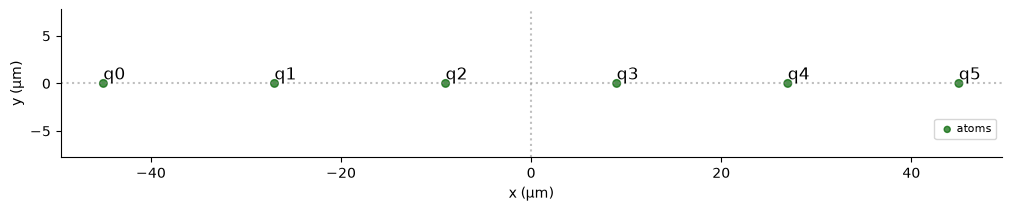

nearest-neighbour coupling: 6.222 rad/µs


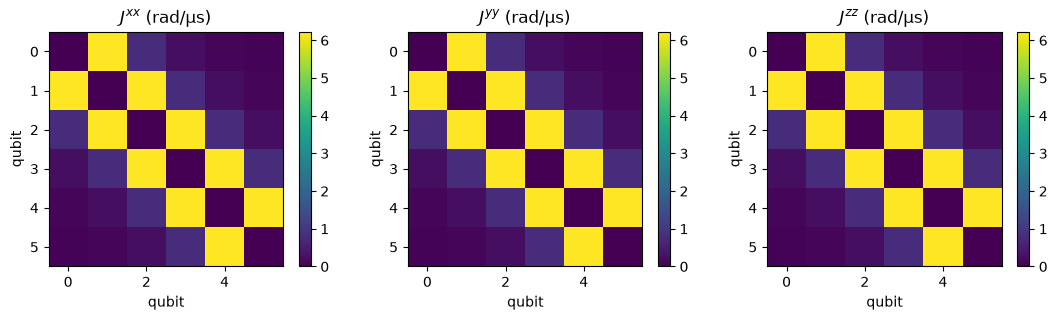

In [2]:
n = 6
reg = pulser.Register.rectangle(1, n, spacing=18.0, prefix="q")
reg.draw()

pos = torch.tensor(np.array([c.as_array() for c in reg.qubits.values()]))
r = torch.cdist(pos, pos)
C3 = MockDevice.interaction_coeff_xy  # rad/µs · µm³
J_dip = torch.where(r > 0, C3 / r**3, torch.zeros_like(r))

anisotropy = torch.tensor([1.0, 1.0, 1.0], dtype=torch.float64)  # (Jxx, Jyy, Jzz) / J_dip
J = anisotropy[:, None, None] * J_dip  # shape (3, n, n)
print(f"nearest-neighbour coupling: {J_dip[0, 1]:.3f} rad/µs")

fig, axes = plt.subplots(1, 3, figsize=(11, 3))
for ax, Jk, name in zip(axes, J, ("$J^{xx}$", "$J^{yy}$", "$J^{zz}$")):
    im = ax.imshow(Jk, cmap="viridis")
    ax.set_title(name + " (rad/µs)")
    ax.set_xlabel("qubit"); ax.set_ylabel("qubit")
    fig.colorbar(im, ax=ax)
fig.tight_layout()

## 2. Drive, discretized

The global drive is built from pulser waveforms (Blackman π-pulse, linear detuning ramp) and sampled at the middle of
each time step: emu-mps holds `omega[k]`, `delta[k]`, `phi[k]` constant on `[target_times[k], target_times[k+1]]`.

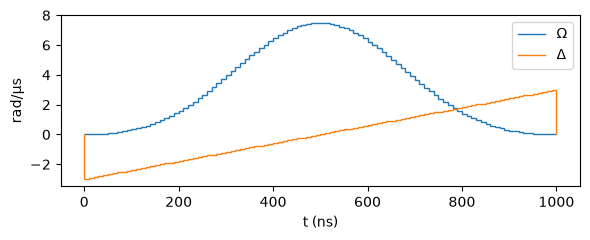

In [3]:
T, dt = 1000, 10  # ns
nsteps = T // dt
target_times = [dt * k for k in range(nsteps + 1)]
t_mid = np.arange(dt // 2, T, dt)

omega_wf = pulser.BlackmanWaveform(T, area=np.pi)
delta_wf = pulser.RampWaveform(T, -3.0, 3.0)
omega_1d = torch.tensor(omega_wf.samples.as_array()[t_mid])
delta_1d = torch.tensor(delta_wf.samples.as_array()[t_mid])

# shape (nsteps, n): one column per qubit (a local drive would differ per column)
omega = omega_1d[:, None].repeat(1, n)
delta = delta_1d[:, None].repeat(1, n)
phi = torch.zeros(nsteps, n, dtype=torch.float64)

plt.figure(figsize=(6, 2.5))
plt.stairs(omega_1d, target_times, label=r"$\Omega$")
plt.stairs(delta_1d, target_times, label=r"$\Delta$")
plt.xlabel("t (ns)"); plt.ylabel("rad/µs"); plt.legend(); plt.tight_layout()

## 3. Exact dynamics

Dense $2^n$ state vector, exact piecewise-constant propagation $\psi \leftarrow e^{-iH_k\,dt}\psi$.
We start from the Néel state $|010101\rangle$ and record $\langle n_j\rangle(t)$.

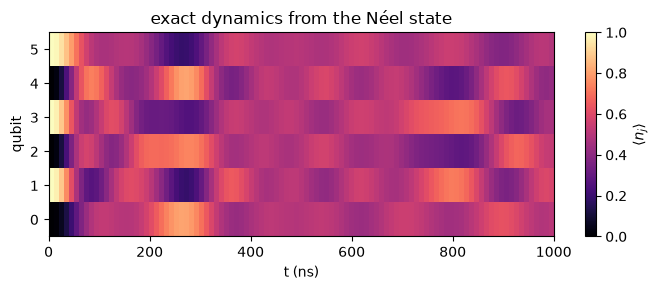

In [4]:
X = torch.tensor([[0, 1], [1, 0]], dtype=dtype)
Y = torch.tensor([[0, -1j], [1j, 0]], dtype=dtype)
Z = torch.tensor([[1, 0], [0, -1]], dtype=dtype)
N = torch.tensor([[0, 0], [0, 1]], dtype=dtype)


def op(single, i):
    # single-qubit operator on qubit i; qubit 0 is the most significant bit
    return reduce(torch.kron, [single if k == i else torch.eye(2, dtype=dtype) for k in range(n)])


H_int = sum(
    J[a, i, j] * op(P, i) @ op(P, j)
    for a, P in enumerate((X, Y, Z))
    for i in range(n)
    for j in range(i + 1, n)
)
N_ops = [op(N, j) for j in range(n)]


def H_at(k):
    return H_int + sum(
        omega[k, j] / 2 * (torch.cos(phi[k, j]) * op(X, j) + torch.sin(phi[k, j]) * op(Y, j))
        - delta[k, j] * N_ops[j]
        for j in range(n)
    )


neel = "".join(str(j % 2) for j in range(n))
psi = torch.zeros(2**n, dtype=dtype)
psi[int(neel, 2)] = 1.0

occ_exact = [torch.stack([torch.vdot(psi, Nj @ psi).real for Nj in N_ops])]
for k in range(nsteps):
    psi = torch.linalg.matrix_exp(-1j * H_at(k) * dt / 1000) @ psi  # dt in µs
    occ_exact.append(torch.stack([torch.vdot(psi, Nj @ psi).real for Nj in N_ops]))
occ_exact = torch.stack(occ_exact)  # (nsteps + 1, n)
psi_exact = psi

plt.figure(figsize=(7, 3))
plt.imshow(occ_exact.T, aspect="auto", origin="lower", extent=(0, T, -0.5, n - 0.5), cmap="magma", vmin=0, vmax=1)
plt.colorbar(label=r"$\langle n_j \rangle$")
plt.xlabel("t (ns)"); plt.ylabel("qubit"); plt.title("exact dynamics from the Néel state")
plt.tight_layout()

## 4. Same problem with emu-mps

The `SequenceData` is the only input; `interaction_matrix` is a callable of time returning the `3 x n x n` stack.
Qubit reordering is off so qubit indices match the exact simulation.

In [5]:
def make_sequence_data(lindblad_ops=()):
    return SequenceData(
        omega=omega.to(dtype),
        delta=delta.to(dtype),
        phi=phi.to(dtype),
        interaction_matrix=lambda t: J,  # 3 x n x n => Heisenberg
        qubit_ids=tuple(reg.qubit_ids),
        bad_atoms=(False,) * n,
        lindblad_ops=list(lindblad_ops),
        state_prep_error=0.0,
        target_times=target_times,
        eigenstates=["0", "1"],
        hamiltonian_type=HamiltonianType.XY,
        has_stochastic_noise=False,
    )


eval_times = [k / nsteps for k in range(nsteps + 1)]
psi0_mps = MPS.from_state_amplitudes(eigenstates=("0", "1"), amplitudes={neel: 1.0})


def make_config(*observables):
    return MPSConfig(
        observables=list(observables),
        initial_state=psi0_mps,
        optimize_qubit_ordering=False,
        precision=1e-9,
        log_level=logging.WARN,
    )


config = make_config(Occupation(evaluation_times=eval_times), StateResult(evaluation_times=[1.0]))
res = MPSBackend._run_from_sequence_data(make_sequence_data(), config)

occ_mps = torch.stack([torch.as_tensor(o) for o in res.occupation])
mps_final = res.state[-1]
psi_mps = reduce(lambda a, b: torch.tensordot(a, b, dims=1), mps_final.factors).reshape(-1).cpu()

print(f"final-state fidelity |<psi_exact|psi_mps>|^2 = {abs(torch.vdot(psi_exact, psi_mps))**2:.12f}")
print(f"max |<n_j>_mps - <n_j>_exact| over all times = {(occ_mps - occ_exact).abs().max():.2e}")
print(f"max bond dimension = {mps_final.get_max_bond_dim()}")

emu-mps allows only {'energy', 'statistics', 'energy_second_moment', 'bitstrings', 'occupation', 'correlation_matrix', 'energy_variance'} observables with `optimize_qubit_ordering = True`. you provided unsupported {'state'} using `optimize_qubit_ordering = False` instead.


final-state fidelity |<psi_exact|psi_mps>|^2 = 0.999984267871
max |<n_j>_mps - <n_j>_exact| over all times = 1.02e-03
max bond dimension = 8


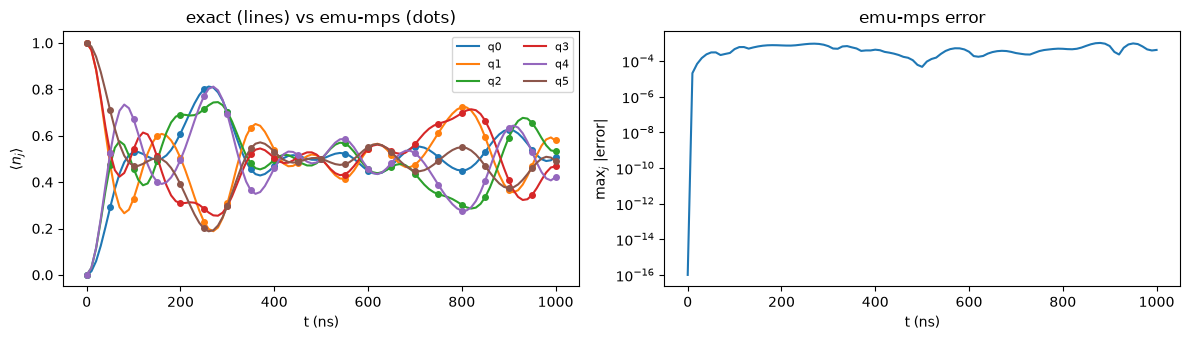

In [6]:
times = np.array(target_times)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.5))
for j in range(n):
    (line,) = ax1.plot(times, occ_exact[:, j], label=f"q{j}")
    ax1.plot(times[::5], occ_mps[::5, j], "o", color=line.get_color(), ms=4)
ax1.set_xlabel("t (ns)"); ax1.set_ylabel(r"$\langle n_j \rangle$")
ax1.set_title("exact (lines) vs emu-mps (dots)"); ax1.legend(ncol=2, fontsize=8)

ax2.semilogy(times, (occ_mps - occ_exact).abs().max(dim=1).values + 1e-16)
ax2.set_xlabel("t (ns)"); ax2.set_ylabel(r"max$_j$ |error|"); ax2.set_title("emu-mps error")
fig.tight_layout()

## 5. Small noise

Noise is passed as single-qubit Lindblad operators in `SequenceData.lindblad_ops`.
We take them from a pulser `NoiseModel` (dephasing + depolarizing, rates in 1/µs) through emu-base's
`get_lindblad_operators`. emu-mps then runs the Monte Carlo wave-function method: one call = one trajectory,
so we average over trajectories.

Reference: the exact Lindblad master equation on the $2^n \times 2^n$ density matrix,
$\dot\rho = -i[H,\rho] + \sum_k L_k\rho L_k^\dagger - \tfrac12\{L_k^\dagger L_k, \rho\}$, integrated with RK4.

In [7]:
noise_model = pulser.NoiseModel(dephasing_rate=0.2, depolarizing_rate=0.1)  # 1/µs
lindblad_ops = [
    L
    for noise_type in noise_model.noise_types
    for L in get_lindblad_operators(noise_type=noise_type, noise_model=noise_model, interact_type="XY")
]
print(noise_model.noise_types, f"-> {len(lindblad_ops)} single-qubit Lindblad operators")

n_traj = 50
noisy_seq = make_sequence_data(lindblad_ops)
traj = []
for _ in range(n_traj):
    r_ = MPSBackend._run_from_sequence_data(noisy_seq, make_config(Occupation(evaluation_times=eval_times)))
    traj.append(torch.stack([torch.as_tensor(o) for o in r_.occupation]))
traj = torch.stack(traj)  # (n_traj, nsteps + 1, n)
occ_mc = traj.mean(0)
occ_mc_err = traj.std(0) / n_traj**0.5

('dephasing', 'depolarizing') -> 4 single-qubit Lindblad operators


In [8]:
# exact Lindblad reference, RK4 with 1 ns substeps
Ls = [op(L, j) for L in lindblad_ops for j in range(n)]
LdL = sum(L.mH @ L for L in Ls)


def rhs(rho, H):
    H_eff = H - 0.5j * LdL
    out = -1j * (H_eff @ rho - rho @ H_eff.mH)
    for L in Ls:
        out += L @ rho @ L.mH
    return out


n_sub = 10
h = dt / 1000 / n_sub  # µs
rho = torch.zeros(2**n, 2**n, dtype=dtype)
rho[int(neel, 2), int(neel, 2)] = 1.0
occ_lindblad = [torch.stack([torch.trace(Nj @ rho).real for Nj in N_ops])]
purity = [torch.trace(rho @ rho).real]
for k in range(nsteps):
    H = H_at(k)
    for _ in range(n_sub):
        k1 = rhs(rho, H)
        k2 = rhs(rho + h / 2 * k1, H)
        k3 = rhs(rho + h / 2 * k2, H)
        k4 = rhs(rho + h * k3, H)
        rho = rho + h / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
    occ_lindblad.append(torch.stack([torch.trace(Nj @ rho).real for Nj in N_ops]))
    purity.append(torch.trace(rho @ rho).real)
occ_lindblad = torch.stack(occ_lindblad)

print(f"max |MC - Lindblad| = {(occ_mc - occ_lindblad).abs().max():.3f} "
      f"(MC std. error up to {occ_mc_err.max():.3f})")
print(f"max |noisy - noiseless| (exact) = {(occ_lindblad - occ_exact).abs().max():.3f}")
print(f"final purity Tr(rho^2) = {purity[-1]:.3f}")

max |MC - Lindblad| = 0.051 (MC std. error up to 0.024)
max |noisy - noiseless| (exact) = 0.120
final purity Tr(rho^2) = 0.156


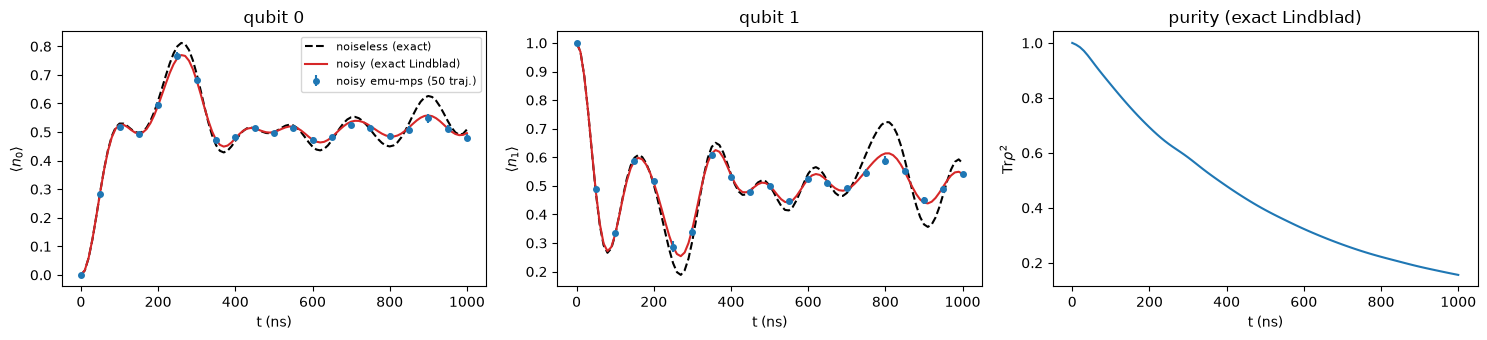

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, j in zip(axes[:2], (0, 1)):
    ax.plot(times, occ_exact[:, j], "k--", label="noiseless (exact)")
    ax.plot(times, occ_lindblad[:, j], "C3", label="noisy (exact Lindblad)")
    ax.errorbar(times[::5], occ_mc[::5, j], yerr=occ_mc_err[::5, j], fmt="o", color="C0", ms=4,
                label=f"noisy emu-mps ({n_traj} traj.)")
    ax.set_xlabel("t (ns)"); ax.set_ylabel(rf"$\langle n_{j} \rangle$"); ax.set_title(f"qubit {j}")
axes[0].legend(fontsize=8)

axes[2].plot(times, purity)
axes[2].set_xlabel("t (ns)"); axes[2].set_ylabel(r"Tr$\rho^2$"); axes[2].set_title("purity (exact Lindblad)")
fig.tight_layout()

**Reading the plots.** Without noise emu-mps reproduces the exact dynamics. The small residual error is the
TDVP time-splitting error of the long-range couplings: it scales as $dt^2$ (final infidelity 1.6e-5 at
`dt = 10` ns, 4.2e-6 at `dt = 5` ns); with nearest-neighbour couplings it is at machine precision.
With small noise the Monte Carlo average follows the exact Lindblad solution within its statistical error
(which shrinks as $1/\sqrt{n_{traj}}$), and both deviate visibly from the noiseless curve as the purity drops.
The per-qubit rates are small (0.1-0.2 /µs), but the purity of the 6-qubit state decays roughly as the product
over qubits, so it drops well below 1 within 1 µs. Lower the rates or `T` to see a gentler effect.